In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import joblib
import warnings
warnings.filterwarnings('ignore')

# Load models
rf_url_only = joblib.load('../model/url_only_model.pkl')
rf_hybrid = joblib.load('../model/hybrid_model.pkl')

# Load datasets
df_url = pd.read_csv('../dataset/url_features.csv')
df_combined = pd.read_csv('../dataset/combined_features.csv')

print("URL dataset shape:", df_url.shape)
print("Combined dataset shape:", df_combined.shape)

URL dataset shape: (446176, 30)
Combined dataset shape: (10000, 43)


In [2]:
# Use a sample for SHAP (full dataset is too large)
X_url = df_url.drop('label', axis=1)
X_url_sample = X_url.sample(n=500, random_state=42)

print("Generating SHAP values for URL-only model...")
explainer_url = shap.TreeExplainer(rf_url_only)
shap_values_url = explainer_url.shap_values(X_url_sample)

print("Done!")

Generating SHAP values for URL-only model...
Done!


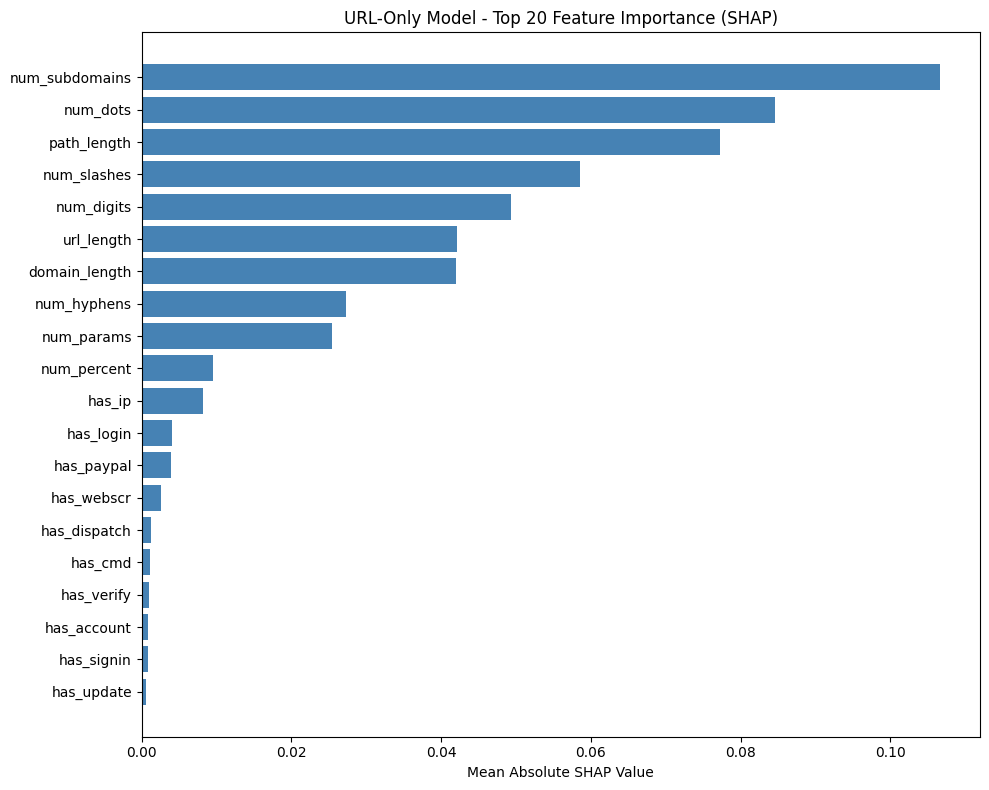

Saved!


In [3]:
# Take SHAP values for malicious class (index 1)
shap_vals_malicious = shap_values_url[:, :, 1]

# Get mean absolute SHAP values
mean_shap = np.abs(shap_vals_malicious).mean(axis=0)

# Create feature importance dataframe
feature_importance = pd.DataFrame({
    'feature': X_url_sample.columns,
    'importance': mean_shap
}).sort_values('importance', ascending=True).tail(20)

# Plot
plt.figure(figsize=(10, 8))
plt.barh(feature_importance['feature'], feature_importance['importance'], color='steelblue')
plt.title('URL-Only Model - Top 20 Feature Importance (SHAP)')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.savefig('../static/shap_url_only.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved!")

In [4]:
# Prepare hybrid model SHAP
df_fetched = df_combined[df_combined['fetch_status'] == 1]
X_hybrid = df_fetched.drop(['url', 'label', 'fetch_status'], axis=1)
X_hybrid_sample = X_hybrid.sample(n=500, random_state=42)

print("Generating SHAP values for hybrid model...")
explainer_hybrid = shap.TreeExplainer(rf_hybrid)
shap_values_hybrid = explainer_hybrid.shap_values(X_hybrid_sample)

print("Type:", type(shap_values_hybrid))
print("Shape:", np.array(shap_values_hybrid).shape)
print("Done!")

Generating SHAP values for hybrid model...
Type: <class 'numpy.ndarray'>
Shape: (500, 40, 2)
Done!


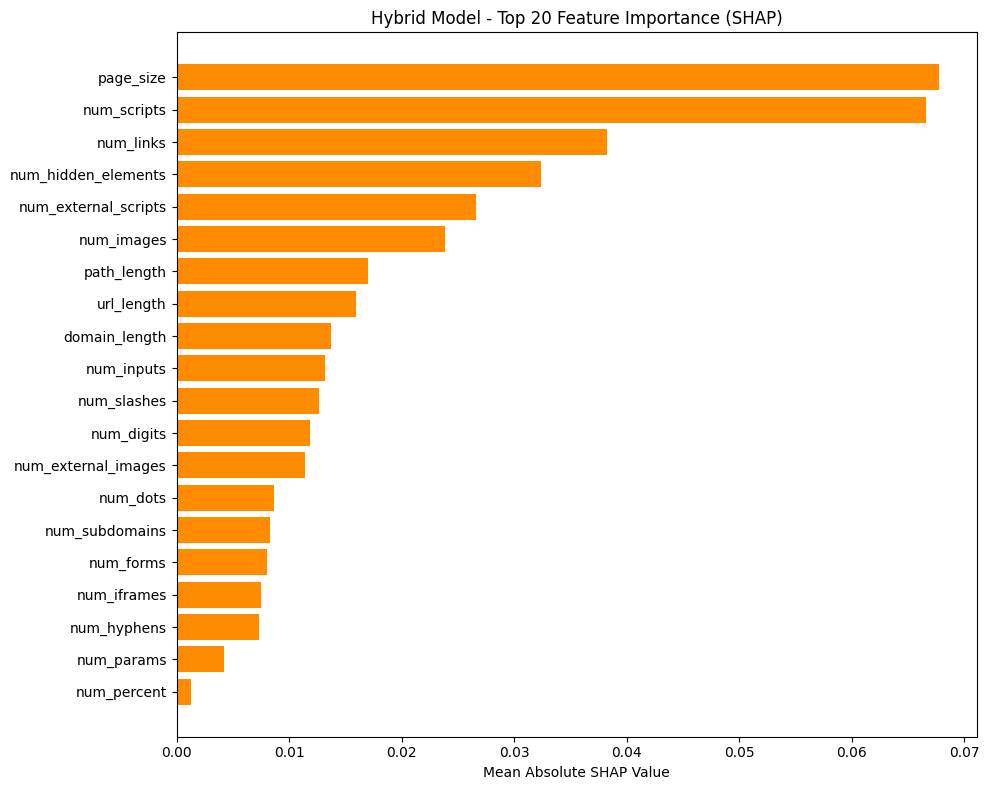

Saved!


In [5]:
# Take SHAP values for malicious class (index 1)
shap_vals_hybrid = shap_values_hybrid[:, :, 1]

# Get mean absolute SHAP values
mean_shap_hybrid = np.abs(shap_vals_hybrid).mean(axis=0)

# Create feature importance dataframe
feature_importance_hybrid = pd.DataFrame({
    'feature': X_hybrid_sample.columns,
    'importance': mean_shap_hybrid
}).sort_values('importance', ascending=True).tail(20)

# Plot
plt.figure(figsize=(10, 8))
plt.barh(feature_importance_hybrid['feature'], feature_importance_hybrid['importance'], color='darkorange')
plt.title('Hybrid Model - Top 20 Feature Importance (SHAP)')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.savefig('../static/shap_hybrid.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved!")

In [6]:
# Save SHAP values for use in web app
import pickle

with open('../model/shap_explainer_url.pkl', 'wb') as f:
    pickle.dump(explainer_url, f)

with open('../model/shap_explainer_hybrid.pkl', 'wb') as f:
    pickle.dump(explainer_hybrid, f)

print("SHAP explainers saved successfully!")

SHAP explainers saved successfully!
